# Actividad Práctica: Árbol de Decisión y Random Forest para Prevenir Riesgos
**Curso:** Agentes Inteligentes - Unidad 3  
**Caso:** Predicción de Deserción Universitaria (`deserta`)

**Documentación de la base de datos:**
- **Naturaleza:** 200 estudiantes ficticios; no se dispone del Excel original del profesor.
- **Estructura:** 5 variables numéricas predictoras y un objetivo binario: `deserta` (1 = sí, 0 = no).
- **Generación y semilla:** NumPy, semilla 42. Promedio: normal (media 12.8, desviación 2.8), limitado a [5, 20]; asistencia: normal (78, 14), limitada a [30, 100]; desaprobados: Poisson (1.4), limitado a [0, 6]; retraso: exponencial (escala 12 días), limitado a [0, 90]; trabajo: 0, 10, 20, 30 o 40 horas, con probabilidades 0.4, 0.2, 0.2, 0.1 y 0.1.
- **Objetivo:** Se suman 0.45 si promedio < 11.5, 0.30 si asistencia < 70%, 0.25 si hay al menos 2 cursos desaprobados y 0.20 si el retraso supera 30 días. La suma se limita a [0, 1] y se compara con un número uniforme para decidir la clase. Se calcula antes del redondeo de las variables. Las horas de trabajo no intervienen directamente: permiten observar una variable sin señal causal incorporada.
- **Inspiración documentada:** El problema y los indicadores académicos y económicos se contextualizan con *Predict Students' Dropout and Academic Success*, de UCI ([ficha y fuente original](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success), DOI: [10.24432/C5MC89](https://doi.org/10.24432/C5MC89)). No se utilizan sus registros ni se reproducen sus distribuciones. Las distribuciones, ponderaciones y umbrales anteriores son supuestos didácticos propios, sin calibración con una universidad real. La base es de elaboración propia y no contiene registros oficiales.
- **Evaluación:** 140 registros para entrenar y 60 para probar, partición estratificada con semilla 42. Ambos modelos usan exactamente las mismas filas; la prueba no interviene en el entrenamiento.

**Reproducción:** Ejecutar todas las celdas en orden. Entorno verificado: Python 3.14.3, NumPy 2.5.4, pandas 3.1.0, Matplotlib 3.11.2 y scikit-learn 1.9.1. En una terminal se puede preparar un entorno aislado:
```sh
python3 -m venv .venv
.venv/bin/python -m pip install numpy==2.5.4 pandas==3.1.0 matplotlib==3.11.2 scikit-learn==1.9.1 ipykernel==7.4.0
```
Seleccionar ese entorno como kernel de Jupyter o VS Code. Los resultados y gráficos ya están guardados en este notebook; no se descargan datos al ejecutarlo.

## Parte 1: El árbol a mano (14 correos de Phishing)

### 1. Cálculo de impureza de Gini ($Gini = 1 - \sum p_i^2$)

- **Gini total del nodo raíz (14 correos: 7 Sí, 7 No):**
  $$Gini(D) = 1 - \left((7/14)^2 + (7/14)^2\right) = 1 - (0.25 + 0.25) = 0.500$$

- **Variable Urgencia:**
  - *Alta (4 correos: 4 Sí, 0 No):* $Gini = 1 - (1^2 + 0^2) = 0.0$
  - *Media (5 correos: 3 Sí, 2 No):* $Gini = 1 - ((3/5)^2 + (2/5)^2) = 1 - (0.36 + 0.16) = 0.480$
  - *Baja (5 correos: 0 Sí, 5 No):* $Gini = 1 - (0^2 + 1^2) = 0.0$
  - **Gini ponderado Urgencia:** $(4/14)(0.0) + (5/14)(0.480) + (5/14)(0.0) = \mathbf{0.171}$

- **Variable Remitente:**
  - *Desconocido (8 correos: 5 Sí, 3 No):* $Gini = 1 - ((5/8)^2 + (3/8)^2) = 0.4688$
  - *Conocido (6 correos: 2 Sí, 4 No):* $Gini = 1 - ((2/6)^2 + (4/6)^2) = 0.4444$
  - **Gini ponderado Remitente:** $(8/14)(0.46875) + (6/14)(4/9) = \mathbf{0.458333\ldots}$

- **Variable Adjunto:**
  - *Sí (7 correos: 4 Sí, 3 No):* $Gini = 1 - ((4/7)^2 + (3/7)^2) = 0.4898$
  - *No (7 correos: 3 Sí, 4 No):* $Gini = 1 - ((3/7)^2 + (4/7)^2) = 0.4898$
  - **Gini ponderado Adjunto:** $(7/14)(0.4898) + (7/14)(0.4898) = \mathbf{0.490}$

- **Variable Enlace corto:**
  - *Sí (6 correos: 3 Sí, 3 No):* $Gini = 1 - ((3/6)^2 + (3/6)^2) = 1 - (0.25 + 0.25) = 0.500$
  - *No (8 correos: 4 Sí, 4 No):* $Gini = 1 - ((4/8)^2 + (4/8)^2) = 1 - (0.25 + 0.25) = 0.500$
  - **Gini ponderado Enlace corto:** $(6/14)(0.500) + (8/14)(0.500) = \mathbf{0.500}$

**Decisión del nodo raíz:** Se selecciona **Urgencia** por tener el menor Gini ponderado ($0.171$), siendo la variable que más reduce la impureza.

---

### 2. Reglas del árbol manual:
1. **SI** Urgencia = "Alta" **ENTONCES** Phishing = Sí
2. **SI** Urgencia = "Baja" **ENTONCES** Phishing = No
3. **SI** Urgencia = "Media" **Y** Remitente = "Desconocido" **ENTONCES** Phishing = Sí
4. **SI** Urgencia = "Media" **Y** Remitente = "Conocido" **ENTONCES** Phishing = No
5. **EN OTRO CASO** Phishing = No

La raíz reduce el Gini de 0.500 a 0.171429 (reducción: 0.328571). En la rama Media, Remitente deja Gini ponderado 0; Adjunto y Enlace corto dejan 0.466667. Por eso se divide por Remitente y todas las hojas quedan puras. El árbol clasifica correctamente los 14 ejemplos, lo que no demuestra su rendimiento en correos nuevos.

La regla **EN OTRO CASO** es una convención de cierre para valores fuera del dominio de la tabla, no una regla aprendida. No permite garantizar que un correo desconocido sea seguro.

**Fotografía del árbol dibujado a mano:** imagen original del equipo convertida a JPEG para que Jupyter la muestre en el notebook.

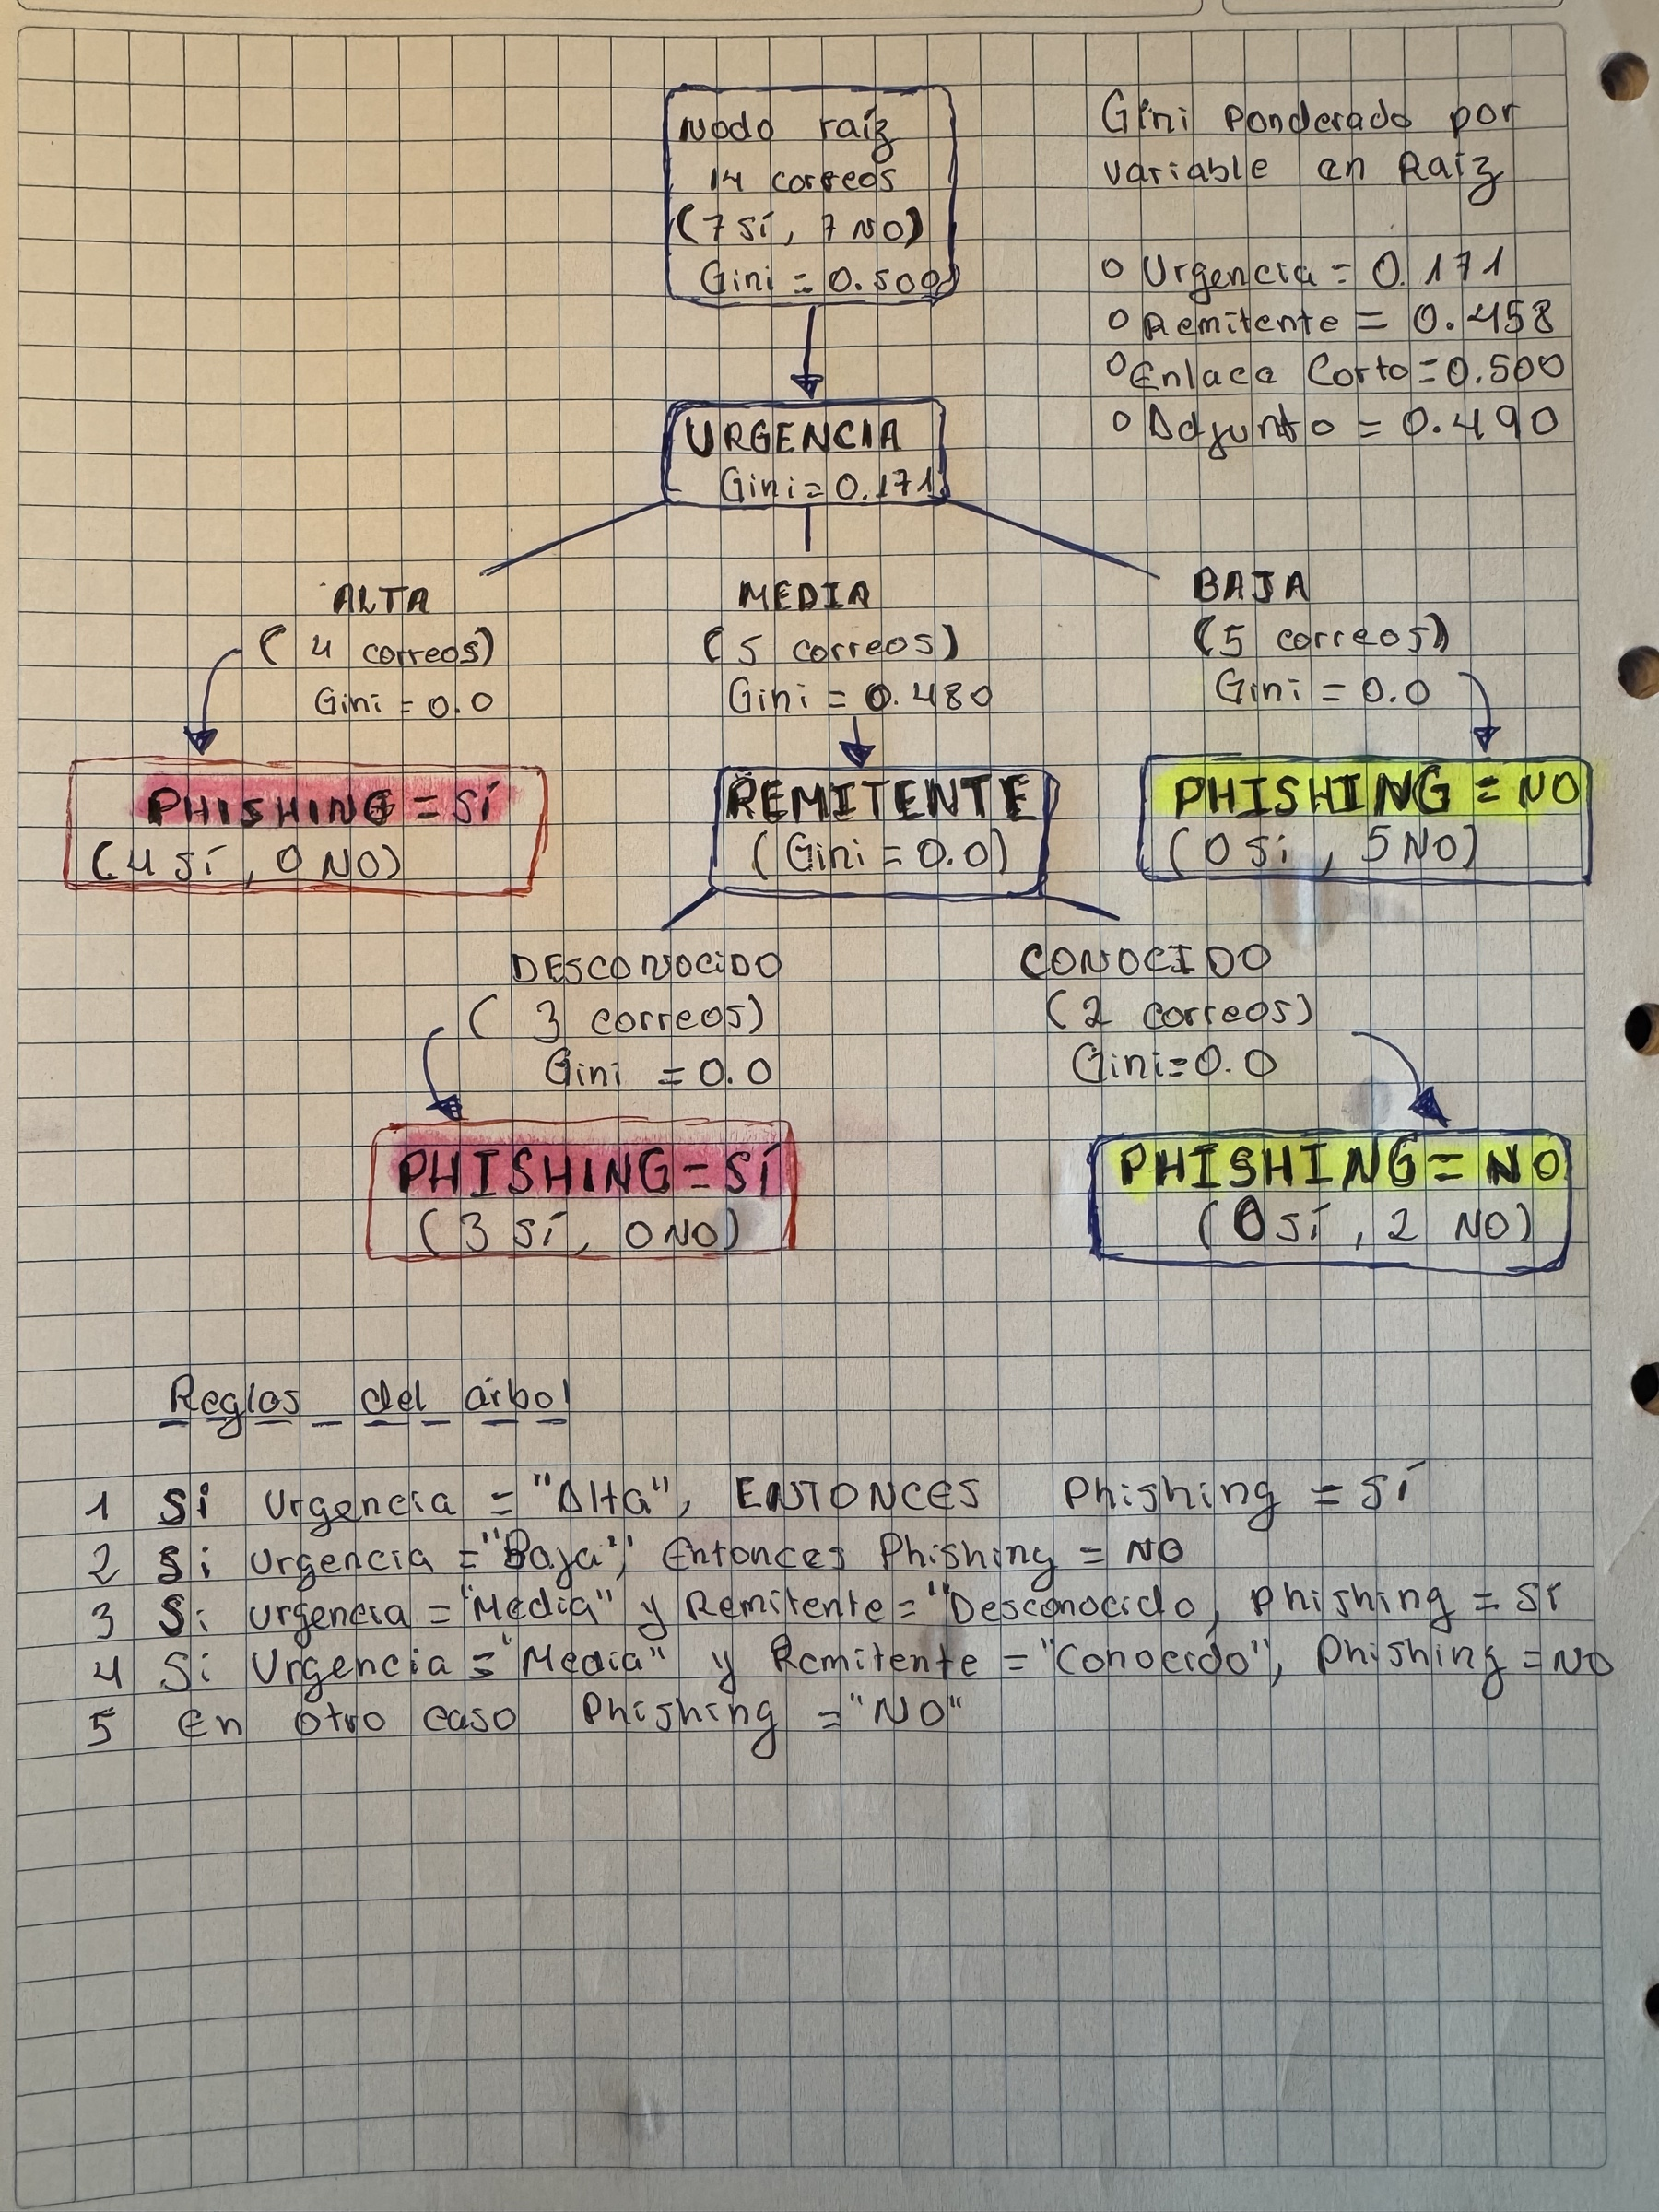

**Alcance de la comprobación:** Se verifican los 14 correos transcritos en `index.html`, que también se muestran a continuación. El Excel y la guía original no están incluidos en la carpeta; falta cotejar la transcripción con el material del docente.

In [1]:
# Comprobación reproducible del árbol manual (tabla transcrita del proyecto)
import pandas as pd
from IPython.display import display

correos = pd.DataFrame([
    ('Alta', 'Desconocido', 'Sí', 'Sí', 'Sí'),
    ('Alta', 'Desconocido', 'No', 'No', 'Sí'),
    ('Alta', 'Conocido', 'Sí', 'No', 'Sí'),
    ('Alta', 'Conocido', 'No', 'Sí', 'Sí'),
    ('Media', 'Desconocido', 'Sí', 'Sí', 'Sí'),
    ('Media', 'Desconocido', 'No', 'No', 'Sí'),
    ('Media', 'Desconocido', 'Sí', 'No', 'Sí'),
    ('Media', 'Conocido', 'No', 'Sí', 'No'),
    ('Media', 'Conocido', 'Sí', 'No', 'No'),
    ('Baja', 'Desconocido', 'No', 'Sí', 'No'),
    ('Baja', 'Desconocido', 'Sí', 'No', 'No'),
    ('Baja', 'Conocido', 'No', 'No', 'No'),
    ('Baja', 'Conocido', 'Sí', 'Sí', 'No'),
    ('Baja', 'Desconocido', 'No', 'No', 'No'),
],
    columns=["Urgencia", "Remitente", "Adjunto", "Enlace_corto", "Phishing"])
correos.index = range(1, 15)
display(correos)

def gini(etiquetas):
    proporciones = etiquetas.value_counts(normalize=True)
    return 1 - (proporciones ** 2).sum()

def gini_ponderado(datos, variable):
    return sum(len(grupo) / len(datos) * gini(grupo["Phishing"])
               for _, grupo in datos.groupby(variable))

filas_gini = []
for variable in correos.columns[:-1]:
    for valor, grupo in correos.groupby(variable):
        si = int((grupo["Phishing"] == "Sí").sum())
        filas_gini.append({"Variable": variable, "Rama": valor, "Sí": si,
                          "No": len(grupo)-si, "Gini rama": gini(grupo["Phishing"])})
display(pd.DataFrame(filas_gini).round(6))
ginis = pd.Series({v: gini_ponderado(correos, v) for v in correos.columns[:-1]}, name="Gini ponderado")
display(ginis.to_frame().round(6))
assert abs(gini(correos["Phishing"]) - 0.5) < 1e-12
assert abs(ginis["Urgencia"] - 6/35) < 1e-12
assert abs(ginis["Remitente"] - 11/24) < 1e-12
assert abs(ginis["Adjunto"] - 24/49) < 1e-12
assert abs(ginis["Enlace_corto"] - 0.5) < 1e-12
assert ginis.idxmin() == "Urgencia"
media = correos[correos["Urgencia"] == "Media"]
print("Raíz elegida:", ginis.idxmin())
print("Gini ponderado en Urgencia Media:")
print({v: round(gini_ponderado(media, v), 6) for v in ["Remitente", "Adjunto", "Enlace_corto"]})

def regla_manual(correo):
    if correo["Urgencia"] == "Alta":
        return "Sí"
    if correo["Urgencia"] == "Baja":
        return "No"
    if correo["Urgencia"] == "Media" and correo["Remitente"] == "Desconocido":
        return "Sí"
    if correo["Urgencia"] == "Media" and correo["Remitente"] == "Conocido":
        return "No"
    return "No"  # Convención de cierre fuera del dominio observado.

assert correos.apply(regla_manual, axis=1).equals(correos["Phishing"])
print("Reglas verificadas sobre los 14 correos: 14/14.")

,Urgencia,Remitente,Adjunto,Enlace_corto,Phishing
1,Alta,Desconocido,Sí,Sí,Sí
2,Alta,Desconocido,No,No,Sí
3,Alta,Conocido,Sí,No,Sí
4,Alta,Conocido,No,Sí,Sí
5,Media,Desconocido,Sí,Sí,Sí
6,Media,Desconocido,No,No,Sí
7,Media,Desconocido,Sí,No,Sí
8,Media,Conocido,No,Sí,No
9,Media,Conocido,Sí,No,No
10,Baja,Desconocido,No,Sí,No


,Variable,Rama,Sí,No,Gini rama
0,Urgencia,Alta,4,0,0.000000
1,Urgencia,Baja,0,5,0.000000
2,Urgencia,Media,3,2,0.480000
3,Remitente,Conocido,2,4,0.444444
4,Remitente,Desconocido,5,3,0.468750
5,Adjunto,No,3,4,0.489796
6,Adjunto,Sí,4,3,0.489796
7,Enlace_corto,No,4,4,0.500000
8,Enlace_corto,Sí,3,3,0.500000


,Gini ponderado
Urgencia,0.171429
Remitente,0.458333
Adjunto,0.489796
Enlace_corto,0.500000


Raíz elegida: Urgencia
Gini ponderado en Urgencia Media:
{'Remitente': np.float64(0.0), 'Adjunto': np.float64(0.466667), 'Enlace_corto': np.float64(0.466667)}
Reglas verificadas sobre los 14 correos: 14/14.


In [2]:
# Parte 0: Generación de datos sintéticos (Caso Deserción) e importaciones
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)
from IPython.display import display, Markdown
import sklearn

np.random.seed(42)
n_filas = 200

# 5 variables numéricas predictoras
promedio_ponderado = np.random.normal(12.8, 2.8, n_filas).clip(5, 20)
porcentaje_asistencia = np.random.normal(78, 14, n_filas).clip(30, 100)
cursos_desaprobados = np.random.poisson(1.4, n_filas).clip(0, 6)
dias_retraso_pension = np.random.exponential(12, n_filas).clip(0, 90)
horas_trabajo_semana = np.random.choice([0, 10, 20, 30, 40], n_filas, p=[0.4, 0.2, 0.2, 0.1, 0.1])

# Lógica estocástica de deserción
riesgo = (
    (promedio_ponderado < 11.5) * 0.45 +
    (porcentaje_asistencia < 70) * 0.30 +
    (cursos_desaprobados >= 2) * 0.25 +
    (dias_retraso_pension > 30) * 0.20
)
riesgo = np.clip(riesgo, 0, 1)  # Una probabilidad debe permanecer entre 0 y 1.
deserta = np.where(np.random.rand(n_filas) < riesgo, 1, 0)

CASO, OBJETIVO = "Desercion", "deserta"
df = pd.DataFrame({
    'promedio_ponderado': promedio_ponderado.round(1),
    'porcentaje_asistencia': porcentaje_asistencia.round(0),
    'cursos_desaprobados': cursos_desaprobados,
    'dias_retraso_pension': dias_retraso_pension.round(0),
    'horas_trabajo_semana': horas_trabajo_semana,
    OBJETIVO: deserta
})

assert df.shape == (200, 6) and df.notna().all().all()
assert df.drop(columns=OBJETIVO).select_dtypes(include="number").shape[1] == 5
assert set(df[OBJETIVO]) == {0, 1}
print(f"Dimensiones del dataset: {df.shape}; semilla: 42; scikit-learn: {sklearn.__version__}")
print("Distribución del objetivo (0 = no deserta, 1 = deserta):")
print(df[OBJETIVO].value_counts().sort_index())
display(df.head())

Dimensiones del dataset: (200, 6); semilla: 42; scikit-learn: 1.9.1
Distribución del objetivo (0 = no deserta, 1 = deserta):
deserta
0    131
1     69
Name: count, dtype: int64


,promedio_ponderado,porcentaje_asistencia,cursos_desaprobados,dias_retraso_pension,horas_trabajo_semana,deserta
0,14.2,83.0,1,33.0,40,1
1,12.4,86.0,0,16.0,20,0
2,14.6,93.0,6,3.0,0,0
3,17.1,93.0,1,0.0,20,0
4,12.1,59.0,0,4.0,10,0


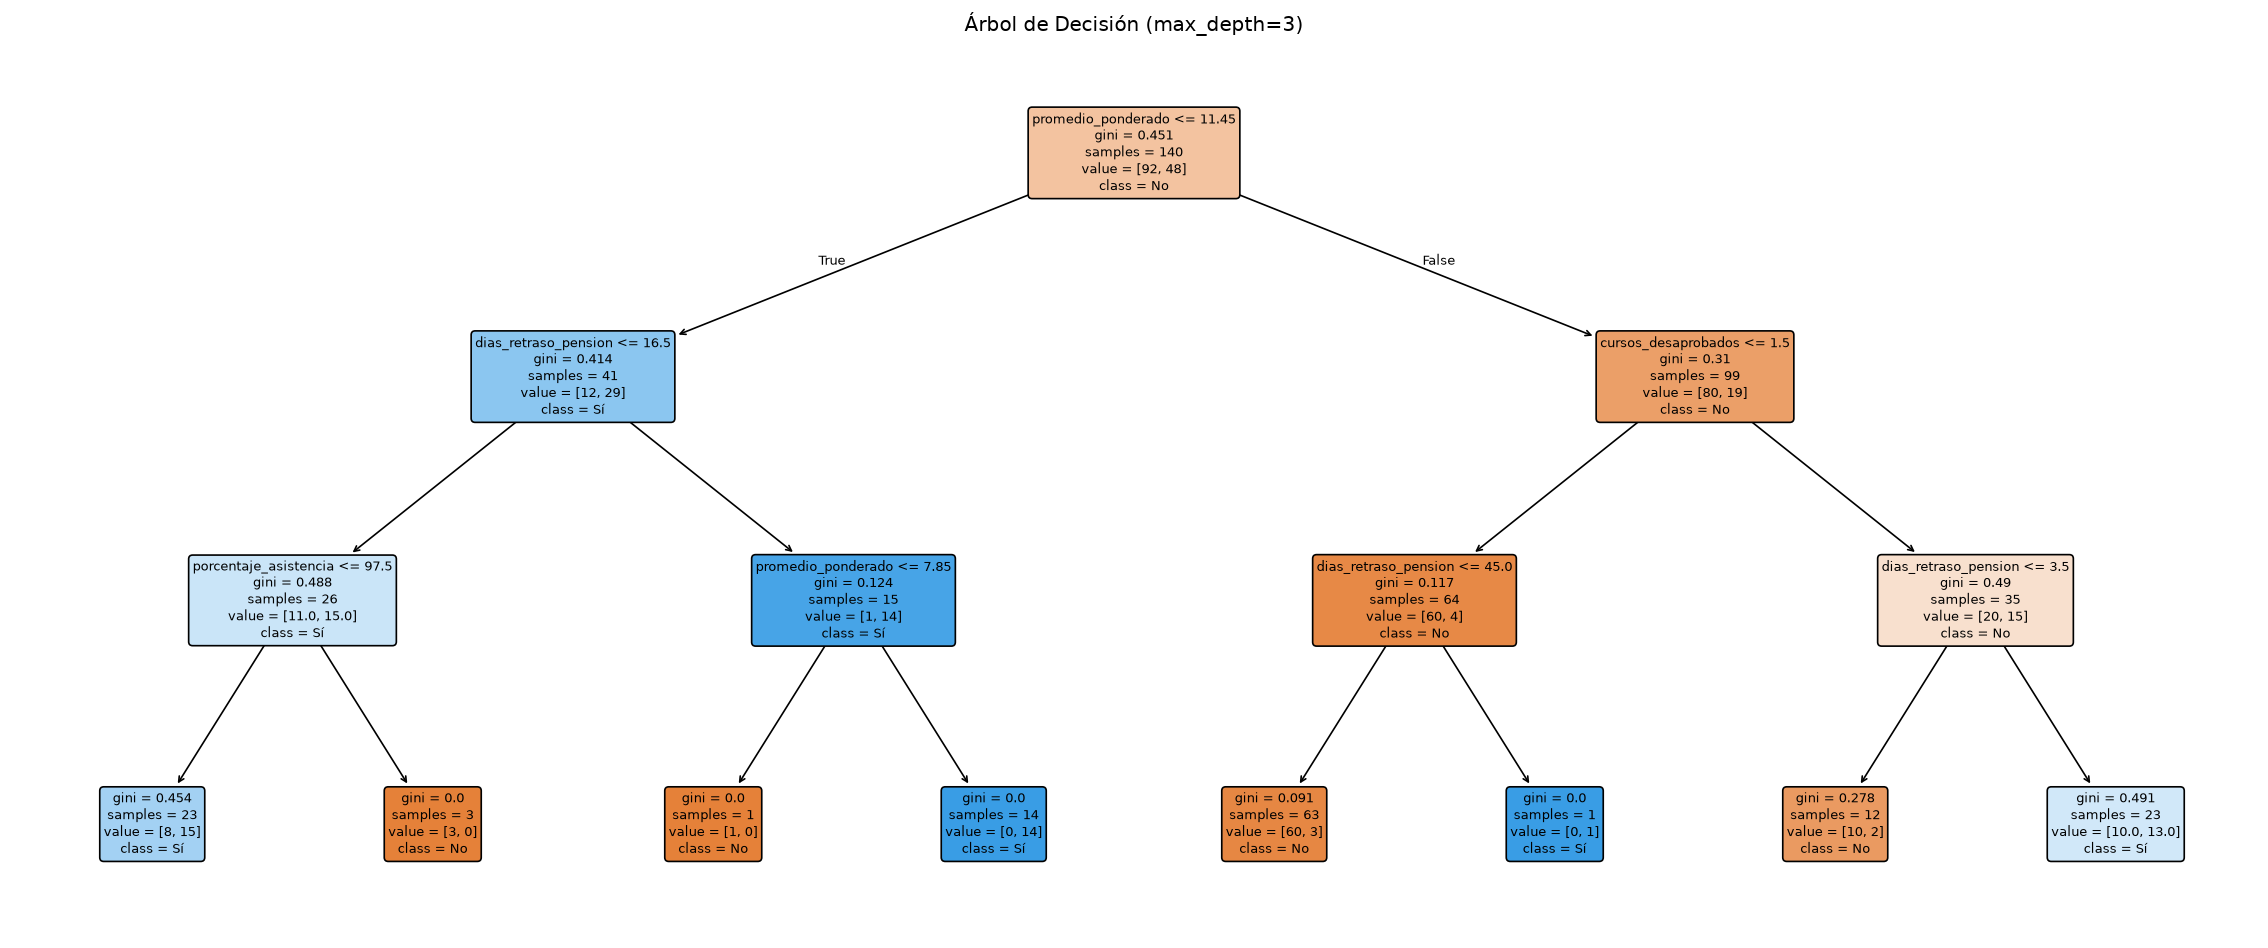

--- Reglas del árbol ---
|--- promedio_ponderado <= 11.45
|   |--- dias_retraso_pension <= 16.50
|   |   |--- porcentaje_asistencia <= 97.50
|   |   |   |--- class: 1
|   |   |--- porcentaje_asistencia >  97.50
|   |   |   |--- class: 0
|   |--- dias_retraso_pension >  16.50
|   |   |--- promedio_ponderado <= 7.85
|   |   |   |--- class: 0
|   |   |--- promedio_ponderado >  7.85
|   |   |   |--- class: 1
|--- promedio_ponderado >  11.45
|   |--- cursos_desaprobados <= 1.50
|   |   |--- dias_retraso_pension <= 45.00
|   |   |   |--- class: 0
|   |   |--- dias_retraso_pension >  45.00
|   |   |   |--- class: 1
|   |--- cursos_desaprobados >  1.50
|   |   |--- dias_retraso_pension <= 3.50
|   |   |   |--- class: 0
|   |   |--- dias_retraso_pension >  3.50
|   |   |   |--- class: 1

Raíz: promedio_ponderado <= 11.45
Árbol profundidad 3 — entrenamiento: 0.8357 prueba: 0.7167
Entrenamiento: 1.0
Prueba:        0.717


In [3]:
# Parte 2: Tu árbol en Python
X = df.drop(columns=OBJETIVO)
y = df[OBJETIVO]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_tr, y_tr)

plt.figure(figsize=(19, 8), dpi=120)
plot_tree(arbol, feature_names=list(X.columns), class_names=["No", "Sí"], filled=True, rounded=True, fontsize=8)
plt.title("Árbol de Decisión (max_depth=3)")
plt.tight_layout()
plt.show()

print("--- Reglas del árbol ---")
print(export_text(arbol, feature_names=list(X.columns)))

print("Raíz:", X.columns[arbol.tree_.feature[0]], "<=", round(arbol.tree_.threshold[0], 2))
print("Árbol profundidad 3 — entrenamiento:", round(arbol.score(X_tr, y_tr), 4),
      "prueba:", round(arbol.score(X_te, y_te), 4))

# Comprobación de sobreajuste con árbol sin límite
libre = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)
print("Entrenamiento:", round(libre.score(X_tr, y_tr), 3))
print("Prueba:       ", round(libre.score(X_te, y_te), 3))

### Respuestas Parte 2:
1. **¿Qué variable eligió el árbol como raíz? ¿Tiene sentido para tu caso?**
   - `promedio_ponderado`, con umbral ≤ 11.45. Tiene sentido dentro de este ejercicio, porque la regla que genera los datos asigna un peso importante a las notas bajas. No demuestra que sea la causa principal de la deserción en una universidad real.

2. **Escribe dos reglas del árbol en palabras simples:**
   - **Regla 1:** SI el promedio es ≤ 11.45, el retraso de pensión es > 16.5 días y el promedio es > 7.85, ENTONCES el modelo predice deserción. La hoja reúne 14 estudiantes de entrenamiento, todos de clase 1. Es una observación de esa muestra, no una certeza para nuevos alumnos.
   - **Regla 2:** SI el promedio es > 11.45, hay como máximo un curso desaprobado (≤ 1.5) y el retraso de pensión es ≤ 45 días, ENTONCES predice permanencia. En esa hoja, 60 de 63 estudiantes de entrenamiento son de clase 0.

3. **¿Por qué el árbol sin límite acierta el 100% en entrenamiento pero menos en prueba?**
   - El árbol sin límite obtiene 1.000 en entrenamiento y 0.717 en prueba: aprende detalles y ruido que no se repiten en estudiantes nuevos. Es una señal de sobreajuste. El árbol de profundidad 3 obtiene 0.836 y 0.717, respectivamente. En esta partición limitar la profundidad reduce la diferencia entre entrenamiento y prueba, pero no mejora la exactitud de prueba; no se fuerza una mejora.

 Árbol (profundidad 3)
Matriz [[VN, FP], [FN, VP]]: [[24, 15], [2, 19]]
              precision    recall  f1-score   support

  No deserta       0.92      0.62      0.74        39
     Deserta       0.56      0.90      0.69        21

    accuracy                           0.72        60
   macro avg       0.74      0.76      0.71        60
weighted avg       0.80      0.72      0.72        60

 Random Forest (100 árboles)
Matriz [[VN, FP], [FN, VP]]: [[32, 7], [6, 15]]
              precision    recall  f1-score   support

  No deserta       0.84      0.82      0.83        39
     Deserta       0.68      0.71      0.70        21

    accuracy                           0.78        60
   macro avg       0.76      0.77      0.76        60
weighted avg       0.79      0.78      0.78        60



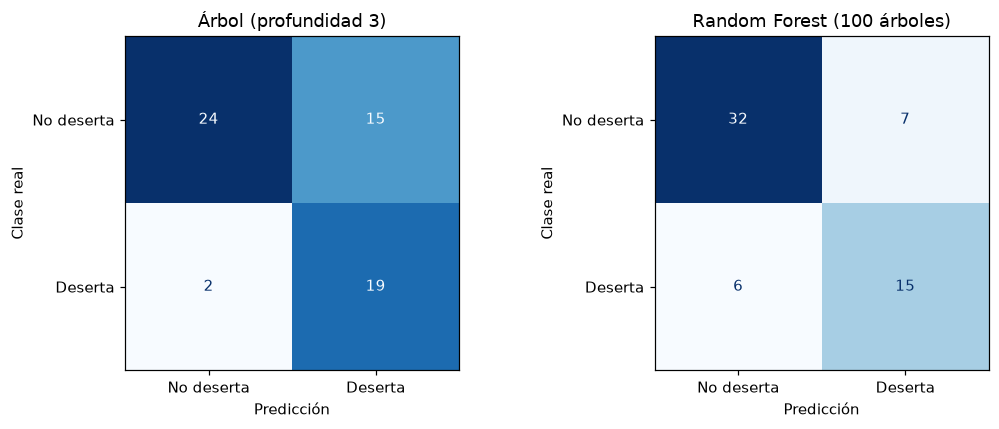

### Tabla comparativa — misma prueba de 60 estudiantes (clase 1 = deserta)

,Accuracy train,Accuracy test,Precisión clase 1,Recall clase 1,F1 clase 1,VN,FP,FN,VP
Modelo,,,,,,,,,
Árbol (profundidad 3),0.8357,0.7167,0.5588,0.9048,0.6909,24,15,2,19
Random Forest (100 árboles),1.0000,0.7833,0.6818,0.7143,0.6977,32,7,6,15


Importancias del bosque entrenado:


,Importancia
promedio_ponderado,0.3714
porcentaje_asistencia,0.2195
dias_retraso_pension,0.1946
cursos_desaprobados,0.1246
horas_trabajo_semana,0.0900


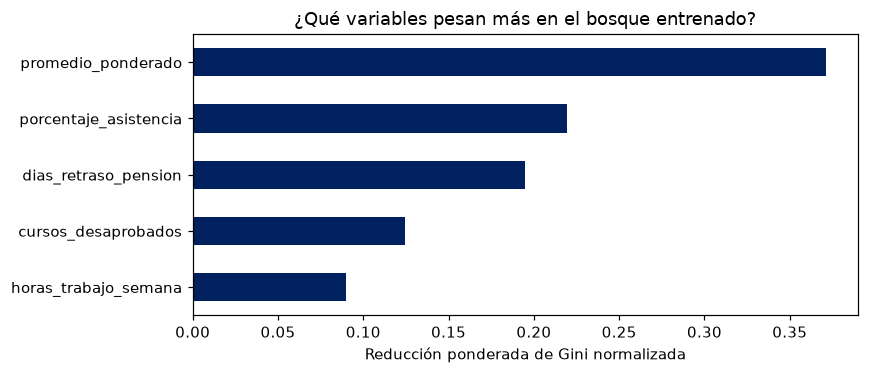

In [4]:
# Parte 3: Random Forest y comparación
# Bootstrap de filas y sqrt(5) = 2 variables candidatas en cada división.
bosque = RandomForestClassifier(n_estimators=100, max_features="sqrt", bootstrap=True, random_state=42)
bosque.fit(X_tr, y_tr)

resultados = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=110)
for ax, (nombre, modelo) in zip(axes, [("Árbol (profundidad 3)", arbol), ("Random Forest (100 árboles)", bosque)]):
    pred = modelo.predict(X_te)
    matriz = confusion_matrix(y_te, pred, labels=[0, 1])
    vn, fp, fn, vp = matriz.ravel()
    resultados.append({
        "Modelo": nombre,
        "Accuracy train": modelo.score(X_tr, y_tr),
        "Accuracy test": accuracy_score(y_te, pred),
        "Precisión clase 1": precision_score(y_te, pred, zero_division=0),
        "Recall clase 1": recall_score(y_te, pred, zero_division=0),
        "F1 clase 1": f1_score(y_te, pred, zero_division=0),
        "VN": vn, "FP": fp, "FN": fn, "VP": vp
    })
    assert vn + fp + fn + vp == len(y_te) == 60
    print("=" * 45, "\n", nombre)
    print("Matriz [[VN, FP], [FN, VP]]:", matriz.tolist())
    print(classification_report(y_te, pred, labels=[0, 1], target_names=["No deserta", "Deserta"], zero_division=0))
    ConfusionMatrixDisplay(matriz, display_labels=["No deserta", "Deserta"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

tabla_comparativa = pd.DataFrame(resultados).set_index("Modelo")
display(Markdown("### Tabla comparativa — misma prueba de 60 estudiantes (clase 1 = deserta)"))
display(tabla_comparativa.round(4))

importancias = pd.Series(bosque.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Importancias del bosque entrenado:")
display(importancias.rename("Importancia").to_frame().round(4))
plt.figure(figsize=(8, 3.5), dpi=110)
importancias.sort_values().plot.barh(color="#002060")
plt.title("¿Qué variables pesan más en el bosque entrenado?")
plt.xlabel("Reducción ponderada de Gini normalizada")
plt.tight_layout()
plt.show()

### Interpretación de la tabla comparativa (clase 1 = deserta)
La tabla anterior se calcula directamente con las predicciones. Accuracy es la **exactitud general**; la **precisión de clase 1** es la proporción de alertas que eran casos positivos.

| Modelo | Accuracy prueba | Precisión clase 1 | Recall clase 1 | F1 clase 1 | VN | FP | FN | VP |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Árbol (profundidad 3) | 0.7167 | 0.5588 | 0.9048 | 0.6909 | 24 | 15 | 2 | 19 |
| Random Forest (100 árboles) | 0.7833 | 0.6818 | 0.7143 | 0.6977 | 32 | 7 | 6 | 15 |

#### Respuestas Parte 3:
1. **¿Qué modelo tiene mejor F1? ¿Por cuánto?**
   - Random Forest: 0.6977 frente a 0.6909, una diferencia de 0.0068 (0.68 puntos porcentuales). Su exactitud mejora 6.67 puntos porcentuales y reduce los falsos positivos de 15 a 7. La precisión pasa de 0.5588 a 0.6818: mejora, pero no se duplica. El árbol detecta 19 de los 21 casos de deserción y el bosque detecta 15. Estas diferencias corresponden a una sola partición sintética, no prueban superioridad general.
2. **¿Qué significa un FN en tu caso? ¿Es peor que un FP?**
   - Un falso negativo es un estudiante que deserta y al que el modelo no alerta; se pierde una oportunidad de apoyo. Un falso positivo recibe una alerta aunque no deserta: consume tiempo de tutoría y puede causar preocupación. Para este caso se prioriza evitar falsos negativos, sin ignorar el costo de las alertas innecesarias.
3. **¿Cuáles son las dos variables que más pesan en el bosque?**
   - `promedio_ponderado` (0.3714) y `porcentaje_asistencia` (0.2195). Los pesos provienen del bosque entrenado. Esta importancia mide la reducción de impureza en entrenamiento, puede favorecer variables con muchos valores y no prueba causalidad. Incluso una variable sin efecto directo en la generación puede recibir peso por ruido.

## Parte 4: Conclusión y Recomendación

**Recomendamos el árbol de profundidad 3 como alerta para tutoría:** detectó 19 de 21 deserciones (2 falsos negativos), frente a 15 del bosque (6 falsos negativos). Aunque produjo 15 falsas alertas frente a 7, priorizamos no omitir estudiantes que necesitan apoyo. Tutoría revisaría cada semana las alertas, vigilaría sobre todo promedio y asistencia y ofrecería apoyo académico o financiero. Es una prueba con datos sintéticos; antes de aplicarla se necesitan datos reales.

## Bono (+2 Puntos): Simulación Interactiva con IA

- **Enlace público informado del proyecto:** https://simulator-agente-sem10.netlify.app/
- **Repositorio de código informado:** https://github.com/Matheuu17/simulator-agente-sem10
- Las correcciones de esta entrega están en el archivo local `index.html`; es necesario publicar esa versión para actualizar Netlify.

### Características del simulador:
1. **Archivo estático único:** HTML, CSS adaptable y JavaScript, con Chart.js como única dependencia externa. Se utilizan fuentes del sistema y no requiere backend.
2. **Identidad visual y aviso:** Azul marino (`#002060`), celeste (`#DCE6F2`) y «Datos sintéticos con fines didácticos».
3. **Pestaña 1:** Usa los 14 correos transcritos, calcula Gini por rama y compara las cuatro variables. Urgencia obtiene 0.171429 y Enlace corto, 0.500000. Construye las ramas y explica las reglas de cierre.
4. **Pestaña 2:** Genera 200 registros por caso, con semilla 42 y variables y probabilidades propias para deserción, phishing, spam, ITS y extorsión. La deserción mantiene su generador de JavaScript: no es la misma base que la de Python, por lo que sus métricas no deben coincidir con este notebook.
5. **Entrenamiento real:** Profundidad de 1 a 10 para ambos modelos; bosque de 1 a 200 árboles, bootstrap, 2 variables candidatas al azar por nodo, árboles con semillas independientes y votación mayoritaria. En empate de votos se elige clase 1. La partición reproducible es de 140 filas para entrenamiento y 60 para prueba, sin estratificación en JavaScript.
6. **Resultados calculados:** Exactitud de entrenamiento y prueba, recall y F1 de clase 1, matrices de confusión e importancia por reducción ponderada de Gini del bosque entrenado. Más profundidad o más árboles pueden cambiar los resultados, sin garantizar mejores métricas ni estabilidad.

### Fuentes metodológicas
- UCI Machine Learning Repository. *Predict Students' Dropout and Academic Success*. [DOI: 10.24432/C5MC89](https://doi.org/10.24432/C5MC89). Referencia contextual para el problema educativo; no se descargaron sus datos.
- scikit-learn. [Decision Trees](https://scikit-learn.org/stable/modules/tree.html) y [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html). Documentación de los métodos y de la importancia por impureza.

**Pendientes para la entrega:** incorporar la fotografía original del árbol a mano y cotejar los 14 correos y los requisitos con el material original del docente, que no está incluido en la carpeta.